# PK basics: Teriparatide

**Goal:** work from published parameters → Cp–time curve → AUC → CL, Vd and half-life → SC absorption.

**Source:** [FDA teriparatide label, Section 12.3](https://www.accessdata.fda.gov/drugsatfda_docs/label/2024/021318s057lbl.pdf).  
Teriparatide is normally administered **subcutaneously (SC)** (drug must move into circulation which gradually respond). 
Teriparatide is a syntetic parathyroid hormone used as anabolic component to treat osteoporosis.


### Key pharmacokinetic parameters

- **F (Bioavailability):** Fraction of drug reaching systemic circulation (0–1).
- **Vd (Volume of distribution):** Apparent volume in which the drug is distributed (L/kg).
- **CL (Clearance):** Volume of plasma cleared of drug per unit time (L/h).
- **T½ (Half-life):** Time for plasma concentration to decrease by 50% (h).
- **kel (Elimination rate):** Rate constant describing drug elimination (h⁻¹).
- **Cp (Plasma concentration):** Drug concentration in plasma (ng/mL).
- **AUC (Drug exposure):** Area under the concentration–time curve (ng·h/mL).

### Key equations (linear, one-compartment PK)

- Elimination rate: $k_{el} = CL/V_d$
- Half-life: $T_{1/2} = 0.693/k_{el}$
- Total exposure: $AUC_{0-\infty} = F \cdot Dose/CL$

FDA = U.S. Food and Drug Administration

# IMPORTS

In [1]:
# IMPORTS



import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 3.5)

## 2. Define parameters

From FDA label for Teriparatide (in women): **F ≈ 0.95**, **Vd ≈ 0.12 L/kg (IV)**, **CL ≈ 62 L/h**, and **SC apparent half-life ≈ 1 h**.  
We use **70 kg** as a body weight. Concentration units: **ng/mL**, numerically equal to **µg/L**.

In [2]:
dose = 20.0        # micrograms
weight = 70.0      # kg
vd_per_kg = 0.12   # L/kg (FDA, IV)
cl = 62.0          # L/h (FDA estimate, women)
F = 0.95           # SC bioavailability

vd = vd_per_kg * weight  # L
kel = cl / vd            # 1/h
half_life_iv = np.log(2) / kel  # h

print(f"Vd = {vd:.2f} L")
print(f"CL = {cl:.1f} L/h")
print(f"kel = {kel:.2f} 1/h")
print(f"Model IV half-life = {half_life_iv * 60:.1f} min")

Vd = 8.40 L
CL = 62.0 L/h
kel = 7.38 1/h
Model IV half-life = 5.6 min


## 3. IV bolus: Cp versus time

At time t: **Cp(t) = (Dose / Vd) × exp(−kel × t)**.  
Immediate IV bolus: **Cp(0) = Dose / Vd**.

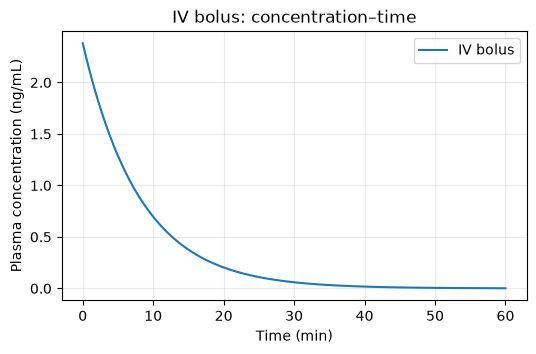

In [3]:
t = np.linspace(0, 1, 400)  # hours
cp_iv = (dose / vd) * np.exp(-kel * t)  # µg/L = ng/mL

plt.plot(t * 60, cp_iv, label="IV bolus")
plt.xlabel("Time (min)")
plt.ylabel("Plasma concentration (ng/mL)")
plt.title("IV bolus: concentration–time")
plt.grid(alpha=0.25)
plt.legend()
plt.show()



## 4. AUC: area under the curve

For a linear IV model, **AUC₀–∞ = Dose / CL**.  


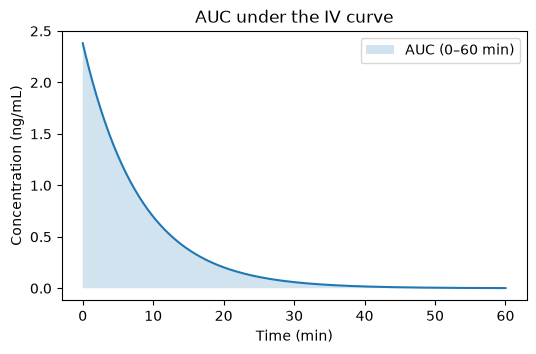

AUC (0–60 min) = 0.3224 ng·h/mL
AUC (0–∞), with tail = 0.3226 ng·h/mL
AUC (Dose/CL) = 0.3226 ng·h/mL


In [4]:
auc_numeric = np.trapezoid(cp_iv, t)  # ng·h/mL
auc_tail = cp_iv[-1] / kel         # ng·h/mL
auc_total = auc_numeric + auc_tail
auc_formula = dose / cl           # µg·h/L = ng·h/mL

plt.plot(t * 60, cp_iv)
plt.fill_between(t * 60, cp_iv, alpha=0.2, label="AUC (0–60 min)")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (ng/mL)")
plt.title("AUC under the IV curve")
plt.legend()
plt.show()

print(f"AUC (0–60 min) = {auc_numeric:.4f} ng·h/mL")
print(f"AUC (0–∞), with tail = {auc_total:.4f} ng·h/mL")
print(f"AUC (Dose/CL) = {auc_formula:.4f} ng·h/mL")

## 5. Log concentration plot

For IV bolus with first-order elimination, **ln(Cp) = log (Cp)** versus time is a straight line with slope **−kel**. (Using log₁₀ instead gives kel = −2.303 × slope.)

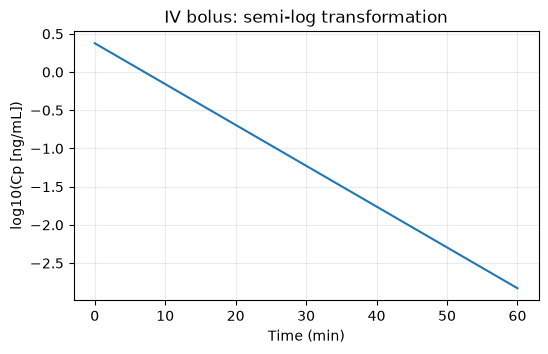

kel from log10 slope = 7.38 1/h


In [5]:
plt.plot(t * 60, np.log10(cp_iv))
plt.xlabel("Time (min)")
plt.ylabel("log10(Cp [ng/mL])")
plt.title("IV bolus: semi-log transformation")
plt.grid(alpha=0.25)
plt.show()

slope = np.polyfit(t, np.log10(cp_iv), 1)[0]  # per hour
print(f"kel from log10 slope = {-np.log(10) * slope:.2f} 1/h")

## 6. Estimate CL and Vd from IV concentration data

For IV bolus: **CL = Dose / AUC₀–∞**, and **Vd = CL / kel**.

In [6]:
cl_est = dose / auc_total
vd_est = cl_est / kel
half_life_est = np.log(2) / kel

print(f"Estimated CL = {cl_est:.2f} L/h")
print(f"Estimated Vd = {vd_est:.2f} L")
print(f"Estimated IV half-life = {half_life_est * 60:.1f} min")

Estimated CL = 62.00 L/h
Estimated Vd = 8.40 L
Estimated IV half-life = 5.6 min


## 7. Subcutaneous (SC) administration

Teriparatide's actual route is **SC**. A simple first-order absorption model is:

**Cp(t) = (F × Dose / Vd) × [ka / (ka − kel)] × [exp(−kel × t) − exp(−ka × t)]**

`ka` is the absorption-rate constant. We choose **ka ≈ 0.693 h⁻¹** as an assumption to reproduce approximately 1-hour terminal SC half-life.

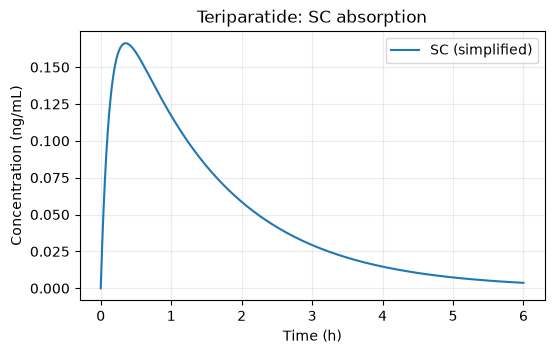

Model SC Tmax ≈ 21 min
Model SC AUC (0–∞) ≈ 0.3064 ng·h/mL
Expected SC AUC = 0.3065 ng·h/mL


In [7]:
ka = 0.693  # 1/h, illustrative absorption constant
t_sc = np.linspace(0, 6, 600)

cp_sc = (F * dose / vd) * (ka / (ka - kel)) * (
    np.exp(-kel * t_sc) - np.exp(-ka * t_sc)
)

plt.plot(t_sc, cp_sc, label="SC (simplified)")
plt.xlabel("Time (h)")
plt.ylabel("Concentration (ng/mL)")
plt.title("Teriparatide: SC absorption")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

auc_sc = np.trapezoid(cp_sc, t_sc) + cp_sc[-1] / ka
print(f"Model SC Tmax ≈ {t_sc[np.argmax(cp_sc)] * 60:.0f} min")
print(f"Model SC AUC (0–∞) ≈ {auc_sc:.4f} ng·h/mL")
print(f"Expected SC AUC = {F * dose / cl:.4f} ng·h/mL")

## 8. Quick comparison and interpretation

- **IV bolus:** no absorption step; Cp is highest at t = 0.
- **SC:** Cp rises, peaks, then falls as absorption and elimination compete.
- **AUC:** total systemic drug exposure.
- **CL:** volume of plasma effectively cleared of drug per unit time.
- **Vd:** apparent distribution volume, not literal anatomical volume.
- **Half-life:** under first-order elimination, ln(2)/kel. The **SC apparent half-life may be absorption-limited**, so it cannot always be used with IV Vd and CL in the same way.
